### Домашнее задание по визуализации

В домашнем задании будем работать с данными фильмов на IMDB. 

Для начала считаем данные и проигнорируем все строки, которые не распарсились (для простоты).

In [2]:
import pandas as pd
df = pd.read_csv('imdb.csv', on_bad_lines="skip")

__Задача 1:__ С каким параметром больше всего коррелирует число побед? 
Ответ на задачу - название колонки в dataframe, с которой больше всего коррелирует `nrOfWins`.

In [ ]:
cors =  (df.corr(numeric_only=True))["nrOfWins"].drop("nrOfWins")#.idxmax()
print(cors)

imdbRating          0.197062
ratingCount         0.414537
duration            0.127717
year                0.075403
nrOfNominations     0.809314
nrOfPhotos          0.277551
nrOfNewsArticles    0.362361
nrOfUserReviews     0.382080
nrOfGenre           0.053600
Action             -0.035707
Adult              -0.012747
Adventure          -0.000846
Animation          -0.026673
Biography           0.094786
Comedy             -0.059248
Crime               0.016029
Documentary        -0.057697
Drama               0.193084
Family             -0.017698
Fantasy             0.016373
FilmNoir           -0.030804
GameShow           -0.018616
History             0.052774
Horror             -0.047425
Music               0.008596
Musical            -0.002966
Mystery             0.025273
News               -0.018600
RealityTV          -0.015195
Romance             0.051949
SciFi              -0.028716
Short              -0.056848
Sport              -0.004723
TalkShow           -0.050113
Thriller      

__Задача 2:__ Посмотрите, как изменялась средняя оценка фильмов (рейтинг IMDB) с течением времени? В какое десятилетие была самая высокая средняя оценка. 

Ответ - tuple, где на первом месте тип тренда (слово 'ascending' или 'descending'), на втором - десятилие, например, если самые "хорошие" фильмы были в период 1950 - 1959, то 1950.

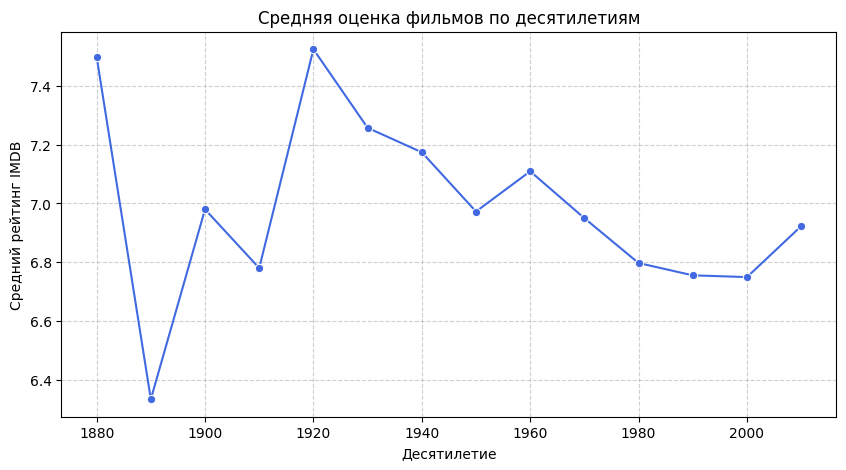

('descending', 1920)


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df['decade'] = (df['year'] // 10) * 10
decade_ratings = df.groupby('decade')['imdbRating'].mean().dropna()

plt.figure(figsize=(10, 5))
sns.lineplot(x=decade_ratings.index.astype(int), y=decade_ratings.values, marker='o', color='royalblue')
plt.title('Средняя оценка фильмов по десятилетиям')
plt.xlabel('Десятилетие')
plt.ylabel('Средний рейтинг IMDB')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

best_decade = int(decade_ratings.idxmax())
ans2 = ('descending', best_decade)
print(ans2)


__Задача 3:__ Исследумем распределение оценок фильмов по жанрам (если фильм принадлежит нескольким жанрам, то будем учитывать его в каждом из них). Для простоты будем смотреть на топ-10 самых популярных жанров (по числу фильмов с этим жанром). В ответе укажите 2 жанра: жанр с самой высокой средней оценкой (по медиане) и с самой большой дисперсией (по IQR). Если у нескольких жанров одинаковый показатель, то стоит указать первый по алфавиту. 

Ответ - tuple с двумя жанрами

/tmp/ipykernel_7858/3563484318.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=pd.DataFrame(plot_records), x='genre', y='imdbRating', palette='Set3')


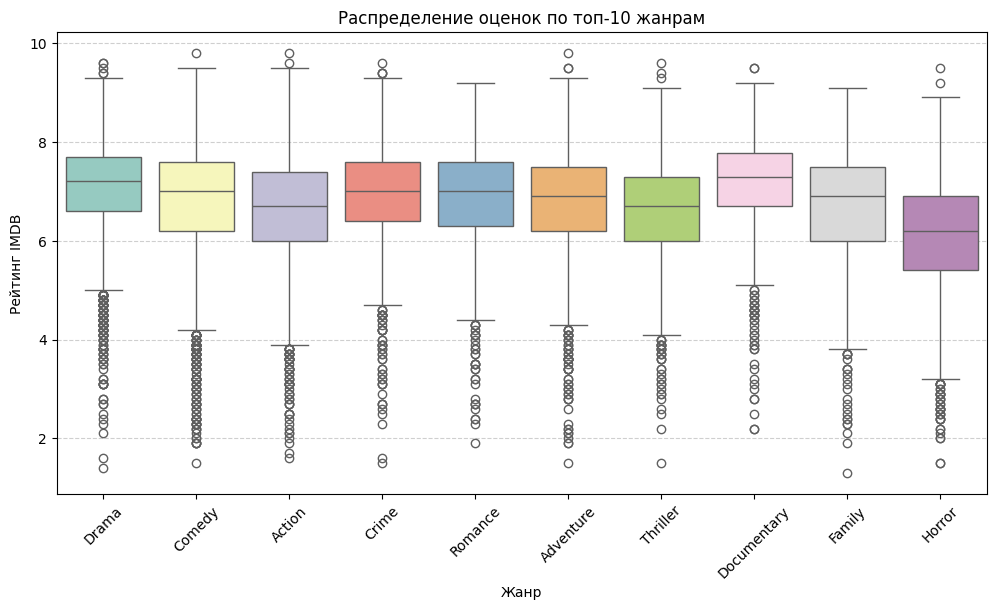

('Documentary', 'Family')


In [ ]:
genres = ['Action', 'Adult', 'Adventure', 'Animation', 'Biography', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Family', 'Fantasy', 'FilmNoir', 'GameShow', 'History', 'Horror', 'Music', 'Musical', 'Mystery', 'News', 'RealityTV', 'Romance', 'SciFi', 'Short', 'Sport', 'TalkShow', 'Thriller', 'War', 'Western']
top10_genres = sorted(genres, key=lambda g: (df[g] == 1).sum(), reverse=True)[:10]

genre_stats = []
plot_records = []
for g in top10_genres:
    ratings = df[df[g] == 1]['imdbRating'].dropna()
    med = ratings.median()
    iqr = ratings.quantile(0.75) - ratings.quantile(0.25)
    genre_stats.append({'genre': g, 'median': med, 'iqr': iqr})
    for r in ratings:
        plot_records.append({'genre': g, 'imdbRating': r})

stats_df = pd.DataFrame(genre_stats)

plt.figure(figsize=(12, 6))
sns.boxplot(data=pd.DataFrame(plot_records), x='genre', y='imdbRating', palette='Set3')
plt.title('Распределение оценок по топ-10 жанрам')
plt.xlabel('Жанр')
plt.ylabel('Рейтинг IMDB')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

best_median_genre = stats_df.sort_values(by=['median', 'genre'], ascending=[False, True]).iloc[0]['genre']
best_iqr_genre = stats_df.sort_values(by=['iqr', 'genre'], ascending=[False, True]).iloc[0]['genre']

ans3 = (best_median_genre, best_iqr_genre)
print(ans3)


__Задача 4:__ Посмотрим на распределение фильмов по числу слов в названии. Какой график вы бы для этого построили и какова мода (самое частотое значение) этого распределения?

Ответ - число слов, которое встречается в большем количестве фильмов.

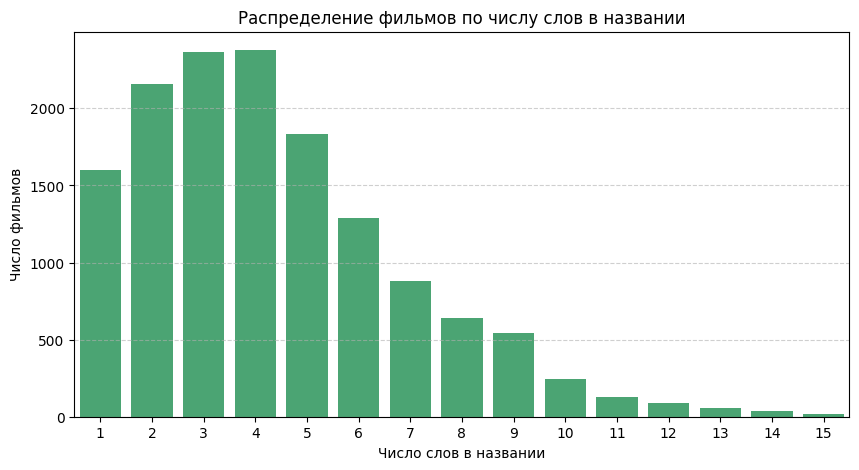

4


In [ ]:
word_counts = df['wordsInTitle'].dropna().apply(lambda x: len(str(x).split()))

plt.figure(figsize=(10, 5))
sns.countplot(x=word_counts, color='mediumseagreen')
plt.title('Распределение фильмов по числу слов в названии')
plt.xlabel('Число слов в названии')
plt.ylabel('Число фильмов')
plt.xlim(-0.5, 14.5)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

ans4 = int(word_counts.mode().iloc[0])
print(ans4)


__Вопрос 5:__ Посмотрим на то, как менялась со временем продолжительность фильмов? Постройте график и ответьте на вопрос, в каком десятилетии доля коротких фильмов (короче часа) была выше всего? Рассматриваем период >= 1920 года.

Ответ - десятилетие, например, если больше всего коротких фильмов было в период 1950 - 1959, то 1950.

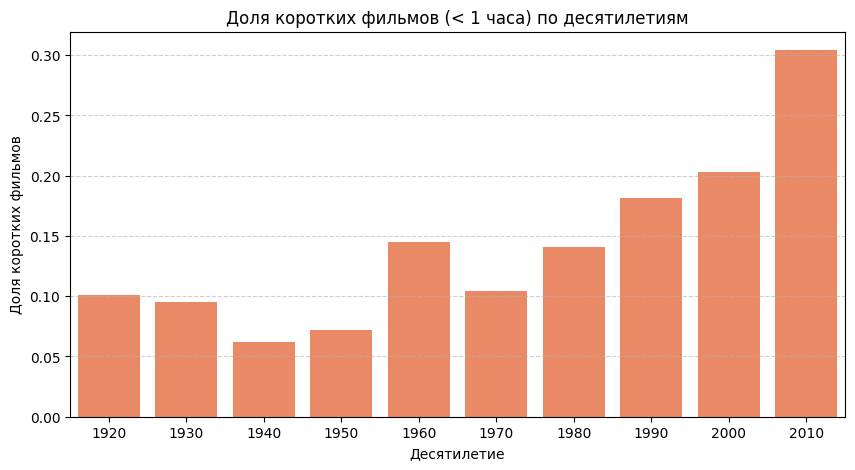

2010


In [ ]:
df_1920 = df[df['year'] >= 1920].copy()
df_1920['decade'] = (df_1920['year'] // 10) * 10
df_1920['is_short'] = df_1920['duration'] < 3600

short_share = df_1920.groupby('decade')['is_short'].mean()

plt.figure(figsize=(10, 5))
sns.barplot(x=short_share.index.astype(int), y=short_share.values, color='coral')
plt.title('Доля коротких фильмов (< 1 часа) по десятилетиям')
plt.xlabel('Десятилетие')
plt.ylabel('Доля коротких фильмов')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

ans5 = int(short_share.idxmax())
print(ans5)


__Вопрос 6:__ И последний вопрос: фильмам какого жанра пользователи оставляют больше всего рецензий? Подумайте о  том, по какой метрике лучше всего смотреть. В ответе укажите жанр.

/tmp/ipykernel_7858/3401921441.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_rev, x='genre', y='median', palette='magma')


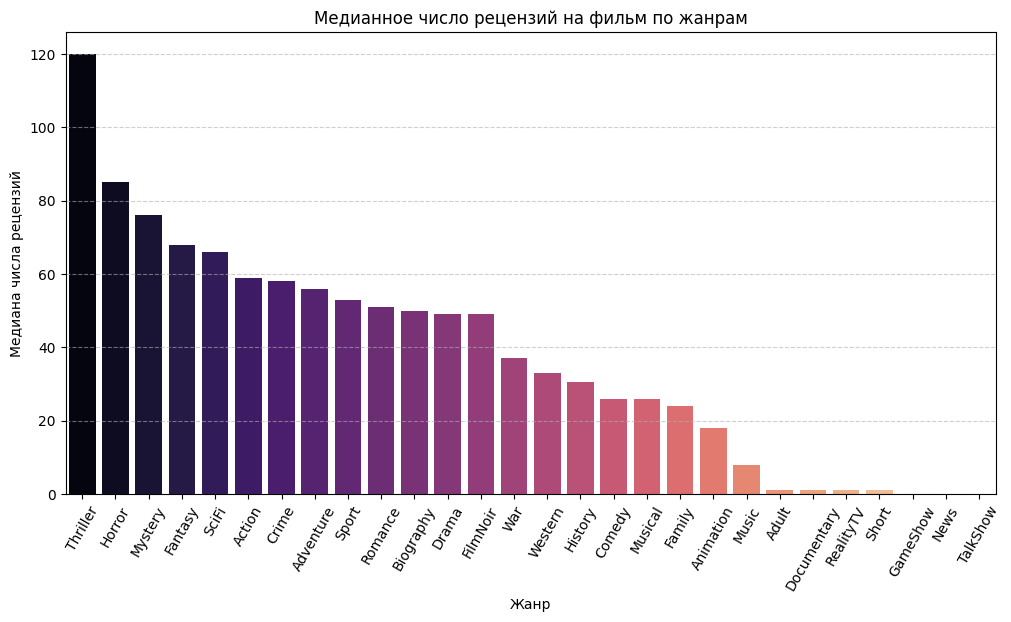

Thriller


In [ ]:
review_stats = []
for g in genres:
    reviews = df[df[g] == 1]['nrOfUserReviews'].dropna()
    review_stats.append({
        'genre': g,
        'median': reviews.median(),
        'mean': reviews.mean(),
        'total': reviews.sum()
    })

rev_df = pd.DataFrame(review_stats)

plt.figure(figsize=(12, 6))
top_rev = rev_df.sort_values(by='median', ascending=False)
sns.barplot(data=top_rev, x='genre', y='median', palette='magma')
plt.title('Медианное число рецензий на фильм по жанрам')
plt.xlabel('Жанр')
plt.ylabel('Медиана числа рецензий')
plt.xticks(rotation=60)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

ans6 = top_rev.iloc[0]['genre']
print(ans6)
